# Backtest: does cleaning the matrix lead to lower-risk portfolios?

The previous notebook ended with a question. With only a year of data, I found that just three to five factors in the correlation matrix stood out from noise and that the raw matrix made the optimizer overconfident about how little risk it was taking. Cleaning helped in a simple year-by-year test, but that test was crude. In this notebook I tested the idea properly: if I had actually used these matrices to manage money over the last nine years, would cleaning them have made a real difference?
A backtest answers that by replaying history as if it were happening in real time. I started in September 2017, after the first full year of data, and stepped forward one month at a time. At each step I did three things. First, I took only the previous year of returns (252 trading days), because that is all an investor would have had at that point. Second, I used that year to build a minimum-variance portfolio, the mix of stocks with the lowest predicted risk. Third, I held that portfolio for the following month (21 trading days) and recorded how it actually performed. Then I moved forward a month and repeated the whole process, 108 times in total. Because I built each portfolio before the month it was tested, none of them could benefit from knowing the future.

At every step, I built the portfolio in four different ways, which differ only in the covariance matrix they use:

- **raw:** the sample covariance matrix, exactly as estimated from the past year.
- **rmt:** the same matrix cleaned with eigenvalue clipping, as in the previous notebook.
- **ledoit-wolf:** Ledoit-Wolf shrinkage, the standard method used in industry and the benchmark I wanted to beat.
- **equal:** 1/73 in every stock. This doesn’t use the matrix at all, so it shows what a naive investor would have got without any risk model.

I also ran the whole backtest twice. The first version allowed short positions, so the optimizer was free to bet against stocks as well as buy them. That makes it very sensitive to errors in the matrix, which is exactly what I wanted to measure. The second version was long-only, with at most 10% in any single stock, which is much closer to what a real fund would be allowed to hold.
Minimum variance only tries to reduce risk; it makes no attempt to pick stocks that will go up. So throughout this notebook, the main measure of success was realized volatility, how much our portfolios actually moved, rather than how much money they made.

## 1. Running the backtest

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_returns
from src.backtest import ESTIMATORS, backtest, summary, bootstrap_vol, rmt_adj_cov

R, sec = load_returns()
rets, info = backtest(R)
rets_lo, info_lo = backtest(R, long=True)
colours = {"raw": "tab:grey", "rmt": "tab:blue", "ledoit-wolf": "tab:orange", "equal": "black"}
rets.index[0].date(), rets.index[-1].date(), info["date"].nunique()

(datetime.date(2017, 9, 27), datetime.date(2026, 9, 25), 108)

The output confirms the setup, where our first portfolio was held from 27 September 2017, exactly one year after the data begins, and the last on 25 September 2026, giving 108 monthly rebalances in total.

## 2. Results with short positions allowed

In [2]:
summary(rets, info).round(3)

,realised vol,annual return,max drawdown,mean predicted vol,monthly turnover,effective holdings,largest weight,gross exposure,return after costs,realised / predicted
raw,0.157,0.091,-0.267,0.086,1.618,3.498,0.230,3.816,0.071,1.826
rmt,0.155,0.112,-0.328,0.092,0.671,6.804,0.201,2.523,0.104,1.697
ledoit-wolf,0.146,0.098,-0.282,0.091,0.990,7.009,0.149,2.826,0.086,1.596
equal,0.179,0.160,-0.338,0.163,0.000,73.000,0.014,1.000,0.160,1.102


**How to read these tables.** Each row is one method, and each column summarises its nine years of out-of-sample returns:
- **realised vol:** the annualised volatility the portfolio actually had. This is the main result, and lower is better.
- **annual return** and **max drawdown:** the average yearly return and the worst fall from a peak. Minimum variance doesn't aim for high returns, so I treated these as context rather than as the target.
- **mean predicted vol** and **realised / predicted:** the risk the matrix expected, and how far reality exceeded it. A ratio of 1 would be a perfect forecast.
- **monthly turnover:** the total value bought and sold at each rebalance, as a share of the portfolio. Selling everything and buying a completely new long-only portfolio would give 2.0.
- **effective holdings:** 1/Σw², roughly how many stocks the portfolio was really spread across (73 for equal weights).
- **largest weight** and **gross exposure:** the biggest single position, and the total size of all positions, long and short. A gross exposure of 3 means, for example, 200% long and 100% short.
- **return after costs:** the annual return minus trading costs, assuming each unit of turnover costs 0.1%, a reasonable figure for large, liquid US stocks.

**What we find:** All three minimum-variance portfolios were less risky than simply holding every stock equally: realized volatility was between 14.6% and 15.7%, against 17.9% for equal weights. So the covariance matrix was clearly worth using. Of the three, Ledoit-Wolf gave the lowest risk at 14.6%, about 7% below the raw matrix, while RMT cleaning barely changed the risk (15.5% against 15.7%).

However, where RMT stood out was in how it built the portfolio. The raw matrix produced extreme positions: on average about 240% long and 140% short, concentrated in the equivalent of just three or four stocks. That is the optimizer chasing the fake low-risk directions I found in the previous notebook. RMT cut the gross exposure from 3.8 to 2.5, nearly doubled the effective number of holdings to about seven, and traded less than half as much as the raw matrix each month (0.67 against 1.62). Ledoit-Wolf sat in between on both counts.

That difference in trading mattered once costs were included. At 0.1% per unit of turnover, trading cost the raw portfolio about two percentage points a year, Ledoit-Wolf about 1.2 and RMT about 0.8. I wouldn’t read too much into the returns themselves, since minimum variance doesn’t aim for them and nine years is a short sample, but the cost drag follows directly from turnover and is much more likely to hold.

Finally, every method still underestimated its own risk, with realized volatility 1.6 to 1.8 times the prediction. The cleaned matrices were a little more honest than the raw one, but the gap is far bigger than estimation noise alone would explain, which matches what I found in the previous notebook, in which markets change from one year to the next.

## 3. Results for long-only portfolios

In [3]:
summary(rets_lo, info_lo).round(3)

,realised vol,annual return,max drawdown,mean predicted vol,monthly turnover,effective holdings,largest weight,gross exposure,return after costs,realised / predicted
raw,0.144,0.114,-0.311,0.111,0.299,14.649,0.100,1.0,0.110,1.297
rmt,0.147,0.109,-0.312,0.112,0.255,14.637,0.099,1.0,0.106,1.307
ledoit-wolf,0.144,0.110,-0.312,0.109,0.282,16.462,0.097,1.0,0.107,1.323
equal,0.179,0.160,-0.338,0.163,0.000,73.000,0.014,1.0,0.160,1.102


**What we find:** Once short positions were banned and each stock was capped at 10%, the three methods became almost indistinguishable amongst themselves. Realized volatility was 14.4% for both raw and Ledoit-Wolf and 14.7% for RMT, all about 20% below equal weights. The constraint itself does much of the cleaning, because the optimizer can no longer take large long-short bets on the directions where the matrix is most wrong. This is a well-known result (Jagannathan and Ma, 2003), and it also explains why every long-only portfolio was less risky than its unconstrained version: 14.4% against 15.7% for the raw matrix.

The long-only forecasts had realized risk about 1.3 times the prediction rather than 1.6 to 1.8. RMT still traded the least (0.26 a month against 0.30 for raw), but the gap was small, and so was the difference in returns after costs. With the constraint doing most of the work, the choice of matrix barely mattered here. Whether RMT’s slightly higher volatility is a real difference or just luck is what I will test in section 7.

## 4. Risk and growth over time

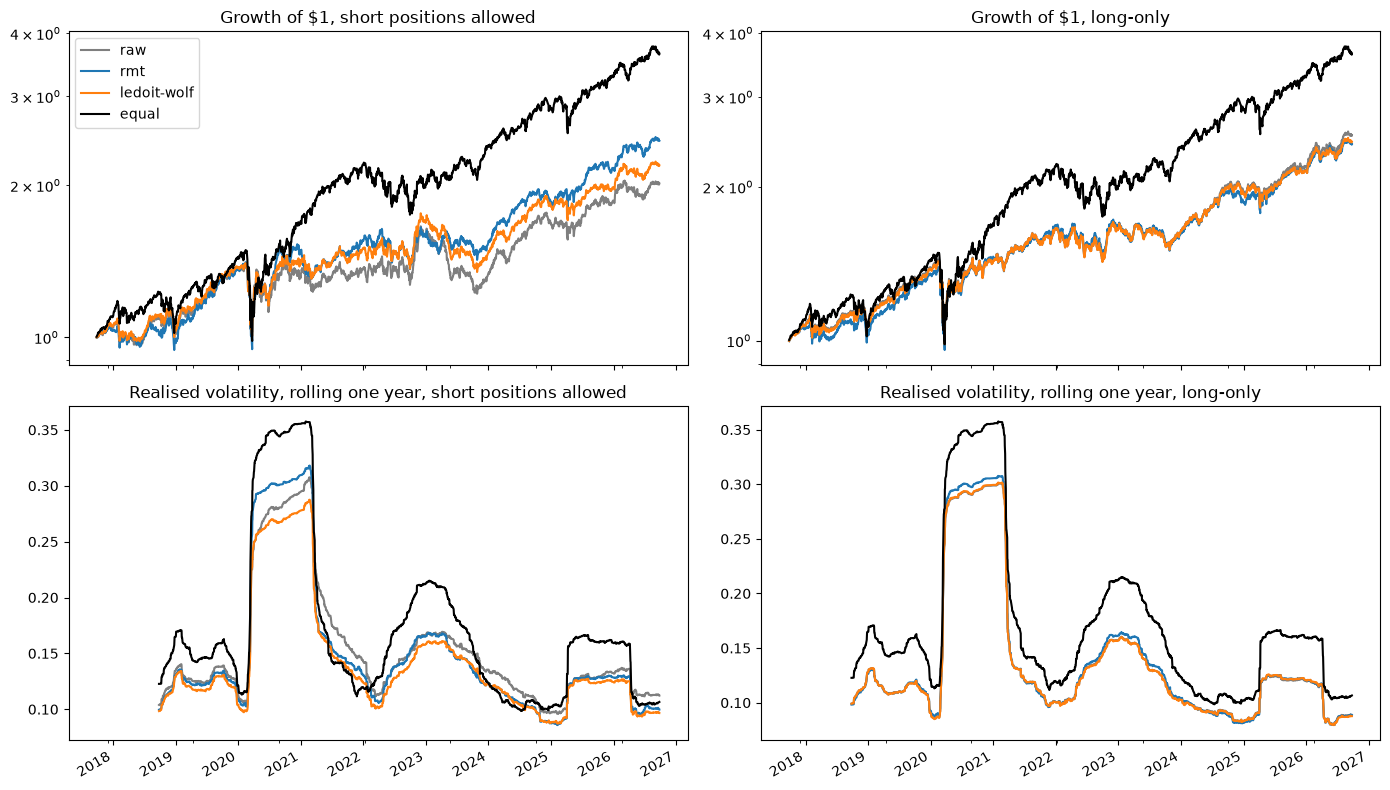

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for col, (r, label) in enumerate([(rets, "short positions allowed"), (rets_lo, "long-only")]):
    for m in r:
        (1 + r[m]).cumprod().plot(ax=axes[0, col], color=colours[m], label=m)
        (r[m].rolling(252).std() * np.sqrt(252)).plot(ax=axes[1, col], color=colours[m], label=m)
    axes[0, col].set_yscale("log")
    axes[0, col].set_title(f"Growth of $1, {label}")
    axes[1, col].set_title(f"Realised volatility, rolling one year, {label}")
    axes[1, col].set_xlabel("")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("../figures/backtest_over_time.png", dpi=150, bbox_inches="tight")

**How to read this figure.** The top row shows how \$1 invested at the start would have grown under each method on a log scale so that equal percentage moves look the same size. The bottom row shows each portfolio's volatility over the previous year, which makes it easier to see when the methods differed and when they moved together.

**What we find.** The bottom row shows that using a covariance matrix reduced risk consistently, not just on average. Equal weights were the riskiest at almost every point, at about 35% in the COVID year against 28 to 32% for the minimum-variance portfolios, and about 21% against 16% during the 2022 rate hikes. With long-only constraints, the three matrix-based methods were almost indistinguishable throughout. With short positions allowed, the methods differed most in the year that included the COVID crash, and that was RMT’s weakest period: its volatility reached about 32%, against roughly 31% for the raw matrix and 29% for Ledoit-Wolf.

The matrix going into that year was estimated in calm conditions, when only a few factors stood out and clipping flattened everything else. When the crash suddenly changed how stocks moved together, that simplified picture turned out to be the one that is most wrong. Ledoit-Wolf, which adjusts every eigenvalue more gently, held up best. Outside that year, RMT and Ledoit-Wolf were usually close, and both sat below the raw matrix.

The top row shows that equal weights grew the most, from $1 to about $3.60, against roughly $2.00\ to $2.50 for the minimum-variance portfolios. That is what I expected: this was a strong bull market led by riskier growth stocks, minimum variance deliberately favors calmer ones, and survivorship bias flatters equal weights. Since minimum variance only aims to reduce risk, I treated the growth curves as context rather than as the result.

## 5. Trading and concentration

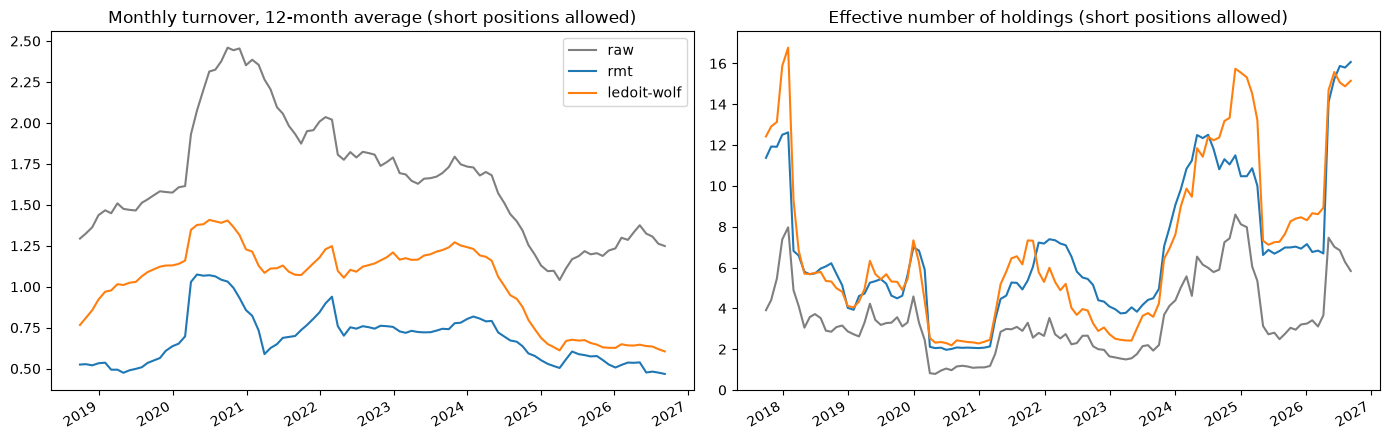

In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.5))
for m in ESTIMATORS:
    d = info[info["method"] == m].set_index("date")
    d["turnover"].rolling(12).mean().plot(ax=a, color=colours[m], label=m)
    d["effective holdings"].plot(ax=b, color=colours[m], label=m)
a.set_title("Monthly turnover, 12-month average (short positions allowed)")
b.set_title("Effective number of holdings (short positions allowed)")
for ax in (a, b):
    ax.set_xlabel("")
a.legend()
plt.tight_layout()
plt.savefig("../figures/backtest_turnover.png", dpi=150, bbox_inches="tight")

**How to read this figure.** The left panel shows how much each method traded at each rebalance, smoothed over twelve months, and the right panel shows how many stocks each portfolio was effectively spread across. Turnover matters in practice because every trade costs money, and a portfolio concentrated in a few positions is more exposed if any one of them goes wrong.

**What we find.** The trading pattern was the clearest difference between the methods, and it held throughout the nine years: RMT always traded the least, Ledoit-Wolf sat in the middle, and the raw matrix traded the most. The raw portfolio is typically bought and sold between 1.3 and 2.4 times its value every month, Ledoit-Wolf between about 0.6 and 1.4, and RMT between about 0.5 and 1.1. On average, RMT traded about a third less than Ledoit-Wolf and less than half as much as raw (0.67 against 0.99 and 1.62). All three traded more in 2020, when the COVID crash changed the matrix sharply from one month to the next, and less from 2024 onwards as markets calmed.

The right panel shows that cleaning also kept the portfolios better diversified. The raw portfolio was usually concentrated in the equivalent of one to eight stocks, while RMT and Ledoit-Wolf were similar to each other and consistently more spread out, reaching 12 to 16 effective holdings in calmer periods. Concentration also followed the market: in the year after the COVID crash, every method collapsed to the equivalent of about two stocks, because when everything moves together, the optimizer can only reduce risk by piling into the few stocks or hedges that still look safe.

So although RMT was slightly riskier than Ledoit-Wolf, it got there with far less trading. In practice, that means lower costs and a more stable portfolio, which is why its return after costs held up best in section 2.

## 6. Are the differences real?

Differences of a few tenths of a percentage point could easily be down to luck, so I tested them. I used a block bootstrap: I rebuilt our nine years of daily returns 2,000 times by stitching together randomly chosen one-month blocks, recomputed each method's volatility every time, and counted how often one method came out lower than the other. I used one-month blocks rather than single days so that calm and turbulent periods stayed intact. If a method came out lower in at least 95% of the resamples, I treated the difference as real.

In [6]:
pairs = [("rmt", "raw"), ("ledoit-wolf", "raw"), ("rmt", "ledoit-wolf")]
pd.DataFrame({(k, f"{a} vs {b}"): bootstrap_vol(r[a], r[b])
              for k, r in [("short positions allowed", rets), ("long-only", rets_lo)] for a, b in pairs}).T.round(4)

difference  95% low  95% high  \
short positions allowed rmt vs raw             -0.0017  -0.0141    0.0113   
                        ledoit-wolf vs raw     -0.0110  -0.0166   -0.0063   
                        rmt vs ledoit-wolf      0.0093   0.0016    0.0186   
long-only               rmt vs raw              0.0022   0.0001    0.0043   
                        ledoit-wolf vs raw      0.0000  -0.0004    0.0004   
                        rmt vs ledoit-wolf      0.0022   0.0002    0.0042   

                                            share of resamples a lower  
short positions allowed rmt vs raw                              0.6635  
                        ledoit-wolf vs raw                      1.0000  
                        rmt vs ledoit-wolf                      0.0015  
long-only               rmt vs raw                              0.0185  
                        ledoit-wolf vs raw                      0.5250  
                        rmt vs ledoit-wolf                      0.0100

**How to read this table.** Each row compares two methods. A negative difference means the first method had lower volatility, and the 95% range shows how much that difference could vary by chance. If the range crosses zero, I can't say the two methods really differ.

**What we found.** With short positions allowed, the only clear-cut result was that Ledoit-Wolf beat the raw matrix: its volatility was 1.1 percentage points lower, the whole 95% range sat below zero, and it came out lower in every one of the 2,000 resamples. RMT’s 0.17-point advantage over raw was not significant. Its range ran from 1.4 points better to 1.1 points worse, and it came out lower in only 66% of resamples, so I can’t say it really reduced risk compared with using the raw matrix. Ledoit-Wolf also beat RMT by about 0.9 points, and that difference was significant. For long-only portfolios, the differences were statistically detectable but tiny. RMT was about 0.2 points riskier than both raw and Ledoit-Wolf, while Ledoit-Wolf and raw were indistinguishable. A gap of 0.2 points on a volatility of about 14.5% is too small to matter in practice, and it confirms what Section 3 suggested: once short positions were ruled out, the constraints did most of the work that cleaning would otherwise do.

## 7. Robustness checks

A result that only holds for one particular setting isn't convincing, so I fixed a set of alternative settings in advance and report all of them, whichever way they point:
- **Window length:** six months (126 days) and two years (504 days) instead of one year. A shorter window means more noise, so I expected cleaning to matter more there.
- **A more generous RMT edge:** the market-adjusted edge from the previous notebook, which keeps more factors.
- **Without the COVID crash:** dropping February to June 2020, to check that one extreme period wasn't driving the result.
- **Higher trading costs:** 0.05%, 0.1% and 0.2% per unit of turnover, to see whether the ranking after costs depends on that assumption.

In [7]:
rows = {}
for win in [126, 252, 504]:
    r, i = backtest(R, window=win, estimators={**ESTIMATORS, "rmt (adjusted)": rmt_adj_cov})
    s = summary(r, i)
    rows[(f"{win} days", "realised vol")] = s["realised vol"]
    rows[(f"{win} days", "turnover")] = s["monthly turnover"]
pd.DataFrame(rows).round(3)

126 days              252 days              504 days  \
               realised vol turnover realised vol turnover realised vol   
raw                   0.179    4.610        0.157    1.618        0.162   
rmt                   0.142    1.031        0.155    0.671        0.175   
ledoit-wolf           0.137    1.504        0.146    0.990        0.158   
rmt (adjusted)        0.138    1.116        0.156    0.772        0.168   
equal                 0.175    0.000        0.179    0.000        0.185   

                         
               turnover  
raw               0.751  
rmt               0.441  
ledoit-wolf       0.578  
rmt (adjusted)    0.468  
equal             0.000

In [8]:
covid = (rets.index >= "2020-02-01") & (rets.index < "2020-07-01")
pd.DataFrame({"all days": rets.std(), "without Feb to Jun 2020": rets[~covid].std()}).mul(np.sqrt(252)).round(3)

,all days,without Feb to Jun 2020
raw,0.157,0.133
rmt,0.155,0.125
ledoit-wolf,0.146,0.121
equal,0.179,0.143


In [9]:
pd.DataFrame({f"{c:.2%} per unit": summary(rets, info, cost=c)["return after costs"] for c in [0.0005, 0.001, 0.002]}).round(3)

,0.05% per unit,0.10% per unit,0.20% per unit
raw,0.081,0.071,0.052
rmt,0.108,0.104,0.096
ledoit-wolf,0.092,0.086,0.074
equal,0.160,0.160,0.160


Window length seems to be one of the most important factors. With only six months of data, the raw matrix was so noisy that its portfolio was riskier than simply holding equal weights (17.9% against 17.5%) and traded 4.6 times its value every month. Cleaning made a large difference here: RMT cut volatility to 14.2% and turnover to about 1.0, close to Ledoit-Wolf’s 13.7%, and the market-adjusted edge did slightly better still at 13.8%. This is exactly the situation random matrix theory is designed for, where there are barely more days than stocks. With two years of data, the result reversed. RMT was the riskiest of the matrix methods (17.5% against 16.2% for raw), and the adjusted edge only partly closed the gap. With more data, the small eigenvalues are estimated more reliably, and some of them describe real low-risk combinations, such as the pairs of similar banks and oil companies found in the previous notebook. The minimum-variance portfolio depends heavily on exactly those directions, so flattening them threw away useful information. Across all three windows, however, RMT always traded the least. Removing February to June 2020 lowered every method’s volatility but didn’t change the ranking: Ledoit-Wolf was still the lowest, then RMT, then raw. RMT’s lead over raw grew from 0.2 to 0.8 percentage points, which suggests that the COVID crash was where it lost most of its advantage. Finally, RMT had the highest return after costs among the matrix-based methods at every cost level from 0.05% to 0.2%, and the gap widened as costs rose because it traded so much less. Equal weights had the highest return overall, but that partly reflects survivorship bias and its larger holdings of riskier growth stocks in a strong bull market, and minimum variance doesn’t aim for return in the first place.

## 8. What this backtest does and doesn't capture

Even though I tried to keep the test as realistic as possible, some simplifications are still worth stating clearly:
- **Trading costs** only enter through the "return after costs" column. They don't affect the volatility figures, and I didn't model market impact or the extra cost of borrowing stocks to short them, which would make the unconstrained portfolios look worse still.
- **Weights were held fixed within each month.** In reality, they drift as prices move between rebalances. This is a standard simplification with very little effect on volatility, but it means our turnover figures slightly understate how much trading would really be needed.
- **The long-only results depend on the cap.** The largest weights often sat right at the 10% limit, so a different cap would change those portfolios. A quick check with a 5% cap gave almost identical volatilities for every method.
- **The Ledoit-Wolf version I used** (scikit-learn's) shrinks towards a scaled identity matrix. Some practitioners use a "constant correlation" target for stocks instead, which can work better, so our comparison is against the standard textbook version rather than every possible variant.
- **Survivorship bias.** As I previously stated, the universe is today's S&P 100, so the absolute returns are flattering. The comparison between methods is fairer, because every method faced the same stocks.
- **One universe and one period.** The results cover 73 large US stocks from 2017 to 2026, and a different market or decade could give a different ranking.

## 9. Conclusions

1. **Ledoit-Wolf gave the lowest risk.** With short positions allowed and a one-year window, it was the only method that significantly beat the raw matrix, and it also beat RMT. It had the lowest risk at every window length I tested. As the industry standard, it was a strong benchmark, and RMT did not beat it on risk.
2. **RMT’s real advantage was stability.** It traded less than half as much as the raw matrix and about a third less than Ledoit-Wolf, held portfolios about twice as diversified as raw, and had the best return after costs among the matrix methods at every cost level I tested.
3. **Cleaning matters most when data is scarce.** With six months of data, the raw matrix was worse than equal weights, and RMT cut risk by almost four percentage points. With two years of data, clipping removed real structure and hurt. Random matrix theory is most useful when the number of days is not much larger than the number of stocks.
4. **Constraints act as cleaning.** In long-only portfolios with a 10% cap, all the methods converged to about 14.5% volatility, in line with Jagannathan and Ma (2003): ruling out short positions stops the optimizer from exploiting noise, so the choice of matrix matters much less.
5. **RMT struggled in sudden crises.** With short positions allowed, it was the riskiest matrix method during the COVID window, because a matrix cleaned on a calm year had flattened the structure that suddenly mattered.

Overall, RMT didn’t give lower-risk portfolios than the standard shrinkage method: it was slightly riskier, by about 0.9 percentage points. But it got there with way less trading and a clear rule for deciding which parts of the matrix are noise. A logical next step would be to combine the two, for example, by shrinking the noise eigenvalues instead of flattening them or by trying nonlinear shrinkage.